# Bird-data cleaning and review

Run the numbered code steps in order, one at a time, starting from the existing cleaning draft. **Cell 1–50 labels are stable step numbers**, independent of Jupyter execution counters such as `In [14]`.

The sequence covers duplicate sensitivity, effort, coordinate screening, species review, sampling summaries and output reports. Cells that save files execute only when you run them. Existing execution outputs are historical until rerun.

Spatial boundary verification and taxonomy review require evidence. The screening box, provisional `ready` status and filenames containing `final` do not establish research readiness. Review the manual CSVs created in Cells 19 and 23, then rerun their dependent steps after recording decisions.


## Setup and input checks

### Cell 1 — Imports and paths

Load the libraries and locate the habitat-risk component. Output folders are created when this cell runs.


In [102]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

# Find project root automatically
current = Path.cwd()
PROJECT_ROOT = None

for folder in [current, *current.parents]:
    test_file = folder / "data" / "interim" / "hri" / "bird_observations_cleaning_draft.csv"
    if test_file.exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "bird_observations_cleaning_draft.csv not found. "
        "Open this notebook inside your habitat_risk project."
    )

INPUT_FILE = PROJECT_ROOT / "data" / "interim" / "hri" / "bird_observations_cleaning_draft.csv"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "hri"
AUDIT_DIR = PROJECT_ROOT / "reports" / "audits"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
REPORT_DIR = PROJECT_ROOT / "reports" / "hri"

for folder in [PROCESSED_DIR, AUDIT_DIR, FIGURE_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("PROJECT ROOT:", PROJECT_ROOT)
print("INPUT:", INPUT_FILE)
print("INPUT EXISTS:", INPUT_FILE.exists())

PROJECT ROOT: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk
INPUT: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/interim/hri/bird_observations_cleaning_draft.csv
INPUT EXISTS: True


### Cell 2 — Load dataset

Continue from `bird_observations_cleaning_draft.csv`. Expected input: 102,929 rows. Inspect the preview before continuing.


In [103]:
df = pd.read_csv(INPUT_FILE, low_memory=False)

print("Dataset loaded successfully.")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Dataset loaded successfully.
Rows: 102929
Columns: 35


,common_name,scientific_name,latitude,longitude,observation_date,year,month,observation_count,duration_minutes,effort_distance_km,protocol,all_species_reported,temperature_max,temperature_min,temperature_mean,precipitation_sum,rain_sum,windspeed_max,windgusts_max,elevation,treecover2000,forest_loss,forest_loss_year,possible_duplicate,observation_date_parsed,invalid_date,observation_year,observation_month,date_fields_disagree,presence_only,observation_count_numeric,count_needs_review,invalid_coordinates,effort_needs_review,needs_review
0,Red-backed Flameback,Dinopium psarodes,6.9035,80.1588,2010-01-07,2010,1,1,60.0,0.805,Traveling,1,29.3,21.7,25.7,0.0,0.0,15.1,30.2,20.0,100,0,0,False,2010-01-07,False,2010,1,False,False,1.0,False,False,False,False
1,Sri Lanka Gray Hornbill,Ocyceros gingalensis,6.9035,80.1588,2010-01-07,2010,1,1,60.0,0.805,Traveling,1,29.3,21.7,25.7,0.0,0.0,15.1,30.2,20.0,100,0,0,False,2010-01-07,False,2010,1,False,False,1.0,False,False,False,False
2,Sri Lanka Hanging-Parrot,Loriculus beryllinus,6.9035,80.1588,2010-01-07,2010,1,1,60.0,0.805,Traveling,1,29.3,21.7,25.7,0.0,0.0,15.1,30.2,20.0,100,0,0,False,2010-01-07,False,2010,1,False,False,1.0,False,False,False,False
3,Chestnut-backed Owlet,Glaucidium castanotum,6.9035,80.1588,2010-01-07,2010,1,1,60.0,0.805,Traveling,1,29.3,21.7,25.7,0.0,0.0,15.1,30.2,20.0,100,0,0,False,2010-01-07,False,2010,1,False,False,1.0,False,False,False,False
4,Crimson-fronted Barbet,Psilopogon rubricapillus,6.9035,80.1588,2010-01-07,2010,1,1,60.0,0.805,Traveling,1,29.3,21.7,25.7,0.0,0.0,15.1,30.2,20.0,100,0,0,False,2010-01-07,False,2010,1,False,False,1.0,False,False,False,False


### Cell 3 — Create permanent source row ID

Preserve the existing source row identifiers. These track rows within the supplied dataset; they are not checklist or sampling-event identifiers.


In [104]:
if "source_row_id" not in df.columns:
    df.insert(0, "source_row_id", np.arange(1, len(df) + 1))

assert df["source_row_id"].is_unique

print("Unique source IDs:", df["source_row_id"].nunique())
print("Total records:", len(df))

display(df[["source_row_id", "common_name", "scientific_name"]].head())

Unique source IDs: 102929
Total records: 102929


,source_row_id,common_name,scientific_name
0,1,Red-backed Flameback,Dinopium psarodes
1,2,Sri Lanka Gray Hornbill,Ocyceros gingalensis
2,3,Sri Lanka Hanging-Parrot,Loriculus beryllinus
3,4,Chestnut-backed Owlet,Glaucidium castanotum
4,5,Crimson-fronted Barbet,Psilopogon rubricapillus


### Cell 4 — Basic dataset validation

Verify the columns required by this workflow before applying decisions.


In [105]:
required_columns = [
    "common_name",
    "scientific_name",
    "latitude",
    "longitude",
    "observation_date",
    "year",
    "month",
    "observation_count",
    "duration_minutes",
    "effort_distance_km",
    "protocol",
    "possible_duplicate",
    "invalid_date",
    "date_fields_disagree",
    "presence_only",
    "observation_count_numeric",
    "count_needs_review",
    "invalid_coordinates",
    "effort_needs_review",
    "needs_review"
]

missing_required = [c for c in required_columns if c not in df.columns]

print("Missing required columns:", missing_required)

assert len(missing_required) == 0, "Required columns are missing."

print("\nDataset structure is valid.")

Missing required columns: []

Dataset structure is valid.


### Cell 5 — Convert boolean fields safely

Standardise stored Boolean flags. The supplied conversion treats unrecognised or missing values as false; inspect unexpected values before relying on the summary.


In [106]:
boolean_columns = [
    "possible_duplicate",
    "invalid_date",
    "date_fields_disagree",
    "presence_only",
    "count_needs_review",
    "invalid_coordinates",
    "effort_needs_review",
    "needs_review"
]

def to_boolean(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)

    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False
        })
        .fillna(False)
        .astype(bool)
    )

for col in boolean_columns:
    df[col] = to_boolean(df[col])

print(df[boolean_columns].dtypes)

possible_duplicate      bool
invalid_date            bool
date_fields_disagree    bool
presence_only           bool
count_needs_review      bool
invalid_coordinates     bool
effort_needs_review     bool
needs_review            bool
dtype: object


### Cell 6 — Overall quality summary

Review overlapping quality flags. Their counts must not be summed as independent sets of observations.


In [107]:
quality_summary = pd.DataFrame({
    "check": [
        "Total records",
        "Unique species",
        "Possible duplicate copies",
        "Invalid dates",
        "Date disagreements",
        "Count issues",
        "Invalid coordinate ranges",
        "Effort issues",
        "Rows needing review"
    ],
    "count": [
        len(df),
        df["scientific_name"].nunique(),
        int(df["possible_duplicate"].sum()),
        int(df["invalid_date"].sum()),
        int(df["date_fields_disagree"].sum()),
        int(df["count_needs_review"].sum()),
        int(df["invalid_coordinates"].sum()),
        int(df["effort_needs_review"].sum()),
        int(df["needs_review"].sum())
    ]
})

display(quality_summary)

,check,count
0,Total records,102929
1,Unique species,25
2,Possible duplicate copies,18411
3,Invalid dates,0
4,Date disagreements,0
5,Count issues,0
6,Invalid coordinate ranges,0
7,Effort issues,20
8,Rows needing review,18431


## Task 2.1 — Duplicate review

### Cell 7 — Duplicate audit

Inspect the 18,411 flagged extra copies. Exact equality does not establish repeated ingestion without original checklist/event identifiers.


In [108]:
duplicate_rows = df[df["possible_duplicate"]].copy()

print("Total records:", len(df))
print("Flagged duplicate copies:", len(duplicate_rows))
print(
    "Percentage flagged:",
    round(len(duplicate_rows) / len(df) * 100, 2),
    "%"
)

display(
    duplicate_rows[
        [
            "source_row_id",
            "common_name",
            "scientific_name",
            "latitude",
            "longitude",
            "observation_date",
            "possible_duplicate"
        ]
    ].head(20)
)

Total records: 102929
Flagged duplicate copies: 18411
Percentage flagged: 17.89 %


,source_row_id,common_name,scientific_name,latitude,longitude,observation_date,possible_duplicate
16,17,Black-capped Bulbul,Rubigula melanictera,6.37210,80.481200,2010-01-01,True
22,23,Sri Lanka Hanging-Parrot,Loriculus beryllinus,6.37210,80.481200,2010-01-01,True
28,29,Sri Lanka Blue-Magpie,Urocissa ornata,6.37210,80.481200,2010-01-01,True
37,38,Layard's Parakeet,Psittacula calthrapae,6.37210,80.481200,2010-01-01,True
48,49,Sri Lanka Drongo,Dicrurus lophorinus,6.37210,80.481200,2010-01-01,True
76,77,Black-capped Bulbul,Rubigula melanictera,6.48910,80.865800,2010-01-04,True
79,80,Red-backed Flameback,Dinopium psarodes,6.48910,80.865800,2010-01-03,True
80,81,Red-backed Flameback,Dinopium psarodes,6.48910,80.865800,2010-01-04,True
83,84,Sri Lanka Hanging-Parrot,Loriculus beryllinus,6.48910,80.865800,2010-01-03,True
86,87,Sri Lanka Green-Pigeon,Treron pompadora,6.48910,80.865800,2010-01-03,True


### Cell 8 — Create duplicate sensitivity dataset

Retain all 102,929 records in the primary view. The expected 84,518-row deduplicated view is for sensitivity analysis only.


In [109]:
df_complete = df.copy()

df_dedup = df.loc[~df["possible_duplicate"]].copy()

print("Complete dataset:", len(df_complete))
print("Deduplicated sensitivity dataset:", len(df_dedup))
print("Difference:", len(df_complete) - len(df_dedup))

Complete dataset: 102929
Deduplicated sensitivity dataset: 84518
Difference: 18411


### Cell 9 — Duplicate sensitivity summary

Compare coverage and count-sensitive summaries. Numeric count sums are descriptive totals, not population abundance estimates.


In [110]:
def dataset_summary(data, name):
    return {
        "dataset": name,
        "records": len(data),
        "species": data["scientific_name"].nunique(),
        "years": data["year"].nunique(),
        "coordinate_pairs": data[["latitude", "longitude"]].drop_duplicates().shape[0],
        "numeric_count_sum": data["observation_count_numeric"].sum(),
        "presence_only_records": data["presence_only"].sum()
    }

duplicate_sensitivity = pd.DataFrame([
    dataset_summary(df_complete, "complete"),
    dataset_summary(df_dedup, "deduplicated_sensitivity")
])

display(duplicate_sensitivity)

,dataset,records,species,years,coordinate_pairs,numeric_count_sum,presence_only_records
0,complete,102929,25,14,7245,233828.0,12743
1,deduplicated_sensitivity,84518,25,14,7245,190977.0,10876


### Cell 10 — Duplicate effect by year

Check whether duplicate effects differ across years. This uses the supplied year field; unresolved date disagreements remain subject to review.


In [111]:
complete_year = df_complete.groupby("year").size().rename("complete_records")
dedup_year = df_dedup.groupby("year").size().rename("deduplicated_records")

duplicate_by_year = pd.concat(
    [complete_year, dedup_year],
    axis=1
).fillna(0)

duplicate_by_year["removed_records"] = (
    duplicate_by_year["complete_records"]
    - duplicate_by_year["deduplicated_records"]
)

duplicate_by_year["removed_percent"] = (
    duplicate_by_year["removed_records"]
    / duplicate_by_year["complete_records"]
    * 100
)

duplicate_by_year = duplicate_by_year.reset_index()

display(duplicate_by_year)

,year,complete_records,deduplicated_records,removed_records,removed_percent
0,2010,1246,1189,57,4.574639
1,2011,1565,1302,263,16.805112
2,2012,1541,1362,179,11.615834
3,2013,1709,1533,176,10.298420
4,2014,2602,2334,268,10.299769
5,2015,3732,3111,621,16.639871
6,2016,4526,3654,872,19.266460
7,2017,5738,4262,1476,25.723249
8,2018,7302,5788,1514,20.734045
9,2019,9016,7500,1516,16.814552


### Cell 11 — Duplicate effect by species

Compare record reductions across recorded species names. These names have not yet been accepted as the final endemic scope.


In [112]:
complete_species = (
    df_complete.groupby(["common_name", "scientific_name"])
    .size()
    .rename("complete_records")
)

dedup_species = (
    df_dedup.groupby(["common_name", "scientific_name"])
    .size()
    .rename("deduplicated_records")
)

duplicate_by_species = pd.concat(
    [complete_species, dedup_species],
    axis=1
).fillna(0)

duplicate_by_species["removed_records"] = (
    duplicate_by_species["complete_records"]
    - duplicate_by_species["deduplicated_records"]
)

duplicate_by_species["removed_percent"] = (
    duplicate_by_species["removed_records"]
    / duplicate_by_species["complete_records"]
    * 100
)

duplicate_by_species = duplicate_by_species.reset_index()

display(
    duplicate_by_species.sort_values(
        "removed_percent",
        ascending=False
    )
)

,common_name,scientific_name,complete_records,deduplicated_records,removed_records,removed_percent
2,Chestnut-backed Owlet,Glaucidium castanotum,1628,1244,384,23.587224
12,Sri Lanka Drongo,Dicrurus lophorinus,2657,2048,609,22.920587
5,Green-billed Coucal,Centropus chlororhynchos,1536,1187,349,22.721354
9,Serendib Scops-Owl,Otus thilohoffmanni,781,604,177,22.663252
22,White-faced Starling,Sturnornis albofrontatus,1180,913,267,22.627119
23,White-throated Flowerpecker,Pachyglossa vincens,1945,1512,433,22.262211
0,Ashy-headed Laughingthrush,Argya cinereifrons,1402,1099,303,21.611983
10,Spot-winged Thrush,Geokichla spiloptera,2632,2066,566,21.504559
18,Sri Lanka Spurfowl,Galloperdix bicalcarata,1926,1517,409,21.235722
11,Sri Lanka Blue-Magpie,Urocissa ornata,2055,1620,435,21.167883


### Cell 12 — Save duplicate audits

Save the duplicate audit and sensitivity summaries under `reports/audits/`. Running this cell replaces those generated audit files.


In [113]:
duplicate_rows.to_csv(
    AUDIT_DIR / "bird_duplicate_audit.csv",
    index=False
)

duplicate_sensitivity.to_csv(
    AUDIT_DIR / "bird_duplicate_sensitivity_summary.csv",
    index=False
)

duplicate_by_year.to_csv(
    AUDIT_DIR / "bird_duplicate_sensitivity_by_year.csv",
    index=False
)

duplicate_by_species.to_csv(
    AUDIT_DIR / "bird_duplicate_sensitivity_by_species.csv",
    index=False
)

print("Duplicate audit files saved.")

Duplicate audit files saved.


## Task 2.2 — Effort review

### Cell 13 — Effort availability flags

Keep missing effort as missing. Availability indicates a supplied value, not that the measurement is valid or comparable across protocols.


In [114]:
df["duration_available"] = df["duration_minutes"].notna()
df["distance_available"] = df["effort_distance_km"].notna()

df["effort_available"] = (
    df["duration_available"]
    | df["distance_available"]
)

df["complete_effort_available"] = (
    df["duration_available"]
    & df["distance_available"]
)

effort_summary = pd.DataFrame({
    "metric": [
        "Total records",
        "Duration available",
        "Duration missing",
        "Distance available",
        "Distance missing",
        "Any effort information available",
        "Both effort variables available"
    ],
    "records": [
        len(df),
        df["duration_available"].sum(),
        (~df["duration_available"]).sum(),
        df["distance_available"].sum(),
        (~df["distance_available"]).sum(),
        df["effort_available"].sum(),
        df["complete_effort_available"].sum()
    ]
})

display(effort_summary)

,metric,records
0,Total records,102929
1,Duration available,91528
2,Duration missing,11401
3,Distance available,65872
4,Distance missing,37057
5,Any effort information available,91714
6,Both effort variables available,65686


### Cell 14 — Detect impossible effort values

Flag negative distance and duration outside the adopted 0–1,440 minute screening range. Review protocol context before interpreting these as confirmed recording errors.


In [115]:
df["invalid_duration"] = (
    (df["duration_minutes"].notna()) &
    (
        (df["duration_minutes"] < 0) |
        (df["duration_minutes"] > 1440)
    )
)

df["invalid_distance"] = (
    (df["effort_distance_km"].notna()) &
    (df["effort_distance_km"] < 0)
)

df["impossible_effort"] = (
    df["invalid_duration"]
    | df["invalid_distance"]
)

print("Invalid duration records:", df["invalid_duration"].sum())
print("Invalid distance records:", df["invalid_distance"].sum())
print("Total impossible effort records:", df["impossible_effort"].sum())

Invalid duration records: 20
Invalid distance records: 0
Total impossible effort records: 20


### Cell 15 — Inspect problematic effort records

Inspect the source rows behind effort flags before recording a decision.


In [116]:
effort_problem_records = df[df["impossible_effort"]].copy()

display(
    effort_problem_records[
        [
            "source_row_id",
            "common_name",
            "observation_date",
            "protocol",
            "duration_minutes",
            "effort_distance_km",
            "invalid_duration",
            "invalid_distance"
        ]
    ]
)

,source_row_id,common_name,observation_date,protocol,duration_minutes,effort_distance_km,invalid_duration,invalid_distance
5727,5728,Black-capped Bulbul,2013-11-12,Traveling,1500.0,12.875,True,False
5729,5730,Red-backed Flameback,2013-11-12,Traveling,1500.0,12.875,True,False
5730,5731,Sri Lanka Gray Hornbill,2013-11-12,Traveling,1500.0,12.875,True,False
5737,5738,Sri Lanka Hanging-Parrot,2013-11-12,Traveling,1500.0,12.875,True,False
5745,5746,Sri Lanka Frogmouth,2013-11-12,Traveling,1500.0,12.875,True,False
5752,5753,Sri Lanka Junglefowl,2013-11-12,Traveling,1500.0,12.875,True,False
5760,5761,Sri Lanka Blue-Magpie,2013-11-12,Traveling,1500.0,12.875,True,False
5770,5771,Sri Lanka Wood-Pigeon,2013-11-12,Traveling,1500.0,12.875,True,False
5771,5772,Chestnut-backed Owlet,2013-11-12,Traveling,1500.0,12.875,True,False
5775,5776,Crimson-backed Flameback,2013-11-12,Traveling,1500.0,12.875,True,False


### Cell 16 — Effort decision

Retain occurrence evidence subject to the other quality checks. Flag invalid effort measurements for exclusion from effort-dependent analyses; missing effort is not zero.


In [117]:
df["effort_decision"] = "keep"

df.loc[
    df["impossible_effort"],
    "effort_decision"
] = "keep_occurrence_exclude_effort"

df["effort_reason"] = "effort valid or missing"

df.loc[
    ~df["effort_available"],
    "effort_reason"
] = "effort information unavailable; missing values retained as missing"

df.loc[
    df["invalid_duration"],
    "effort_reason"
] = "physically implausible survey duration"

df.loc[
    df["invalid_distance"],
    "effort_reason"
] = "negative survey distance"

display(df["effort_decision"].value_counts())

effort_decision
keep                              102909
keep_occurrence_exclude_effort        20
Name: count, dtype: int64

## Task 2.3 — Spatial review

### Cell 17 — Basic coordinate validation

Check missing coordinates and global numeric ranges. Country-boundary membership still needs separate verification.


In [118]:
df["coordinate_missing"] = (
    df["latitude"].isna()
    | df["longitude"].isna()
)

df["coordinate_out_of_global_range"] = (
    (~df["latitude"].between(-90, 90))
    | (~df["longitude"].between(-180, 180))
)

print("Missing coordinates:", df["coordinate_missing"].sum())
print(
    "Globally invalid coordinates:",
    df["coordinate_out_of_global_range"].sum()
)

Missing coordinates: 0
Globally invalid coordinates: 0


### Cell 18 — Sri Lanka screening box

Use the broad envelope only to select obvious review candidates. Passing this box does not verify that a point lies within Sri Lanka.


In [119]:
# Broad screening envelope around Sri Lanka.
# This is NOT a substitute for a real country-boundary spatial join.

SL_LAT_MIN = 5.5
SL_LAT_MAX = 10.1
SL_LON_MIN = 79.3
SL_LON_MAX = 82.2

df["outside_sri_lanka_screen"] = ~(
    df["latitude"].between(SL_LAT_MIN, SL_LAT_MAX)
    &
    df["longitude"].between(SL_LON_MIN, SL_LON_MAX)
)

df.loc[
    df["coordinate_missing"],
    "outside_sri_lanka_screen"
] = True

print(
    "Records outside broad Sri Lanka screening area:",
    df["outside_sri_lanka_screen"].sum()
)

Records outside broad Sri Lanka screening area: 0


### Cell 19 — Create spatial review table

Create a review template only if none exists, preserving previous manual decisions. Inspect the saved file as well as this template preview.


In [120]:
spatial_candidates = df[
    df["coordinate_missing"]
    | df["coordinate_out_of_global_range"]
    | df["outside_sri_lanka_screen"]
].copy()

spatial_review_file = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "hri"
    / "spatial_review_decisions.csv"
)

spatial_review_file.parent.mkdir(
    parents=True,
    exist_ok=True
)

spatial_review_template = spatial_candidates[
    [
        "source_row_id",
        "common_name",
        "scientific_name",
        "latitude",
        "longitude",
        "observation_date"
    ]
].copy()

spatial_review_template["decision"] = "unresolved"
spatial_review_template["reason"] = ""
spatial_review_template["corrected_latitude"] = np.nan
spatial_review_template["corrected_longitude"] = np.nan
spatial_review_template["reviewer"] = ""
spatial_review_template["review_date"] = ""

if not spatial_review_file.exists():
    spatial_review_template.to_csv(
        spatial_review_file,
        index=False
    )

print("Spatial candidates:", len(spatial_candidates))
print("Review file:", spatial_review_file)

display(spatial_review_template.head(20))

Spatial candidates: 0
Review file: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/interim/hri/spatial_review_decisions.csv


,source_row_id,common_name,scientific_name,latitude,longitude,observation_date,decision,reason,corrected_latitude,corrected_longitude,reviewer,review_date


### Cell 20 — Apply spatial review decisions

Apply documented keep, correct, exclude or unresolved decisions. Passing automatic screening is provisional; national-boundary verification remains pending.


In [121]:
df["spatial_decision"] = "keep"
df["spatial_reason"] = "coordinates passed automatic checks"

if spatial_review_file.exists():

    spatial_review = pd.read_csv(spatial_review_file)

    valid_decisions = {
        "keep",
        "correct",
        "exclude",
        "unresolved"
    }

    spatial_review["decision"] = (
        spatial_review["decision"]
        .fillna("unresolved")
        .str.lower()
        .str.strip()
    )

    invalid_decisions = ~spatial_review["decision"].isin(valid_decisions)

    if invalid_decisions.any():
        print(
            "WARNING: invalid manual spatial decisions:",
            spatial_review.loc[
                invalid_decisions,
                "decision"
            ].unique()
        )

    decision_map = spatial_review.set_index(
        "source_row_id"
    )["decision"]

    reason_map = spatial_review.set_index(
        "source_row_id"
    )["reason"]

    df["spatial_decision"] = (
        df["source_row_id"]
        .map(decision_map)
        .fillna(df["spatial_decision"])
    )

    df["spatial_reason"] = (
        df["source_row_id"]
        .map(reason_map)
        .fillna(df["spatial_reason"])
    )

print(df["spatial_decision"].value_counts(dropna=False))

spatial_decision
keep    102929
Name: count, dtype: int64


### Cell 21 — Apply verified coordinate corrections

Apply only evidence-backed coordinate corrections, retaining original coordinates. Recheck corrected coordinates against the country boundary before spatial analysis.


In [122]:
df["latitude_final"] = df["latitude"]
df["longitude_final"] = df["longitude"]

if spatial_review_file.exists():

    spatial_review = pd.read_csv(spatial_review_file)

    corrections = spatial_review[
        spatial_review["decision"].astype(str).str.lower() == "correct"
    ].copy()

    if len(corrections) > 0:

        missing_correction = (
            corrections["corrected_latitude"].isna()
            | corrections["corrected_longitude"].isna()
        )

        if missing_correction.any():
            raise ValueError(
                "A spatial row is marked 'correct' but corrected coordinates are missing."
            )

        lat_map = corrections.set_index(
            "source_row_id"
        )["corrected_latitude"]

        lon_map = corrections.set_index(
            "source_row_id"
        )["corrected_longitude"]

        mask = df["source_row_id"].isin(
            corrections["source_row_id"]
        )

        df.loc[mask, "latitude_final"] = (
            df.loc[mask, "source_row_id"].map(lat_map)
        )

        df.loc[mask, "longitude_final"] = (
            df.loc[mask, "source_row_id"].map(lon_map)
        )

print("Coordinate correction step complete.")

Coordinate correction step complete.


## Task 2.4 — Species scope review

### Cell 22 — Extract all species

List recorded common/scientific name pairs for review. Expected current inventory: 25 scientific names; this is not an authoritative endemic checklist.


In [123]:
species_list = (
    df[
        ["common_name", "scientific_name"]
    ]
    .drop_duplicates()
    .sort_values("scientific_name")
    .reset_index(drop=True)
)

print("Number of species:", len(species_list))

display(species_list)

Number of species: 25


,common_name,scientific_name
0,Ashy-headed Laughingthrush,Argya cinereifrons
1,Sri Lanka Frogmouth,Batrachostomus moniliger
2,Green-billed Coucal,Centropus chlororhynchos
3,Crimson-backed Flameback,Chrysocolaptes stricklandi
4,Sri Lanka Wood-Pigeon,Columba torringtoniae
5,Sri Lanka Drongo,Dicrurus lophorinus
6,Red-backed Flameback,Dinopium psarodes
7,Sri Lanka Spurfowl,Galloperdix bicalcarata
8,Sri Lanka Junglefowl,Gallus lafayettii
9,Spot-winged Thrush,Geokichla spiloptera


### Cell 23 — Create species-scope review file

Review accepted names and endemic eligibility using authoritative sources. Record sources, access dates, notes and include/exclude/unresolved status; do not guess names.


In [124]:
species_review_file = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "hri"
    / "species_scope_review.csv"
)

species_review = species_list.copy()

species_review["scientific_name_original"] = (
    species_review["scientific_name"]
)

species_review["accepted_name"] = ""
species_review["endemic_status"] = "unresolved"
species_review["taxonomic_mismatch"] = "unresolved"
species_review["source"] = ""
species_review["access_date"] = ""
species_review["final_inclusion_status"] = "unresolved"
species_review["review_notes"] = ""

species_review = species_review[
    [
        "common_name",
        "scientific_name_original",
        "accepted_name",
        "endemic_status",
        "taxonomic_mismatch",
        "source",
        "access_date",
        "final_inclusion_status",
        "review_notes"
    ]
]

if not species_review_file.exists():
    species_review.to_csv(
        species_review_file,
        index=False
    )

print("Species review file:")
print(species_review_file)

display(species_review)

Species review file:
/Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/interim/hri/species_scope_review.csv


,common_name,scientific_name_original,accepted_name,endemic_status,taxonomic_mismatch,source,access_date,final_inclusion_status,review_notes
0,Ashy-headed Laughingthrush,Argya cinereifrons,,unresolved,unresolved,,,unresolved,
1,Sri Lanka Frogmouth,Batrachostomus moniliger,,unresolved,unresolved,,,unresolved,
2,Green-billed Coucal,Centropus chlororhynchos,,unresolved,unresolved,,,unresolved,
3,Crimson-backed Flameback,Chrysocolaptes stricklandi,,unresolved,unresolved,,,unresolved,
4,Sri Lanka Wood-Pigeon,Columba torringtoniae,,unresolved,unresolved,,,unresolved,
5,Sri Lanka Drongo,Dicrurus lophorinus,,unresolved,unresolved,,,unresolved,
6,Red-backed Flameback,Dinopium psarodes,,unresolved,unresolved,,,unresolved,
7,Sri Lanka Spurfowl,Galloperdix bicalcarata,,unresolved,unresolved,,,unresolved,
8,Sri Lanka Junglefowl,Gallus lafayettii,,unresolved,unresolved,,,unresolved,
9,Spot-winged Thrush,Geokichla spiloptera,,unresolved,unresolved,,,unresolved,


### Cell 24 — Load species review

Load the saved manual review and inspect statuses and coverage. Resolve duplicate mapping keys and invalid statuses before merging.


In [125]:
species_scope = pd.read_csv(species_review_file)

species_scope["final_inclusion_status"] = (
    species_scope["final_inclusion_status"]
    .fillna("unresolved")
    .str.lower()
    .str.strip()
)

allowed_species_status = {
    "include",
    "exclude",
    "unresolved"
}

bad_status = ~species_scope[
    "final_inclusion_status"
].isin(allowed_species_status)

if bad_status.any():
    print("WARNING: Invalid species statuses found:")
    display(
        species_scope.loc[
            bad_status,
            [
                "scientific_name_original",
                "final_inclusion_status"
            ]
        ]
    )

print(
    species_scope[
        "final_inclusion_status"
    ].value_counts()
)

display(species_scope)

final_inclusion_status
unresolved    25
Name: count, dtype: int64


,common_name,scientific_name_original,accepted_name,endemic_status,taxonomic_mismatch,source,access_date,final_inclusion_status,review_notes
0,Ashy-headed Laughingthrush,Argya cinereifrons,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
1,Sri Lanka Frogmouth,Batrachostomus moniliger,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
2,Green-billed Coucal,Centropus chlororhynchos,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
3,Crimson-backed Flameback,Chrysocolaptes stricklandi,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
4,Sri Lanka Wood-Pigeon,Columba torringtoniae,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
5,Sri Lanka Drongo,Dicrurus lophorinus,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
6,Red-backed Flameback,Dinopium psarodes,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
7,Sri Lanka Spurfowl,Galloperdix bicalcarata,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
8,Sri Lanka Junglefowl,Gallus lafayettii,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN
9,Spot-winged Thrush,Geokichla spiloptera,NaN,unresolved,unresolved,NaN,NaN,unresolved,NaN


### Cell 25 — Save final species scope

The filename `final_species_scope.csv` follows the supplied workflow. If any decisions remain unresolved, this file is a provisional snapshot and does not represent a frozen scope.


In [126]:
FINAL_SPECIES_SCOPE_FILE = (
    PROCESSED_DIR
    / "final_species_scope.csv"
)

species_scope.to_csv(
    FINAL_SPECIES_SCOPE_FILE,
    index=False
)

print("Saved:", FINAL_SPECIES_SCOPE_FILE)

Saved: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/processed/hri/final_species_scope.csv


### Cell 26 — Merge species decisions back to observations

Attach scope decisions while retaining original names. A fallback original name in `accepted_scientific_name` is not evidence of taxonomic verification.


In [127]:
species_status_map = (
    species_scope
    .set_index("scientific_name_original")
    ["final_inclusion_status"]
)

df["species_scope_status"] = (
    df["scientific_name"]
    .map(species_status_map)
    .fillna("unresolved")
)

accepted_name_map = (
    species_scope
    .set_index("scientific_name_original")
    ["accepted_name"]
)

df["accepted_scientific_name"] = (
    df["scientific_name"]
    .map(accepted_name_map)
)

df["accepted_scientific_name"] = (
    df["accepted_scientific_name"]
    .replace("", np.nan)
    .fillna(df["scientific_name"])
)

display(df["species_scope_status"].value_counts())

species_scope_status
unresolved    102929
Name: count, dtype: int64

## Row-level cleaning decisions

### Cell 27 — Date and count decisions

Flag date disagreements, invalid dates and count issues for review. Presence-only observations must not become zero counts.


In [128]:
df["temporal_decision"] = "keep"
df.loc[
    df["invalid_date"] | df["date_fields_disagree"],
    "temporal_decision"
] = "unresolved"
df["count_decision"] = "keep"
df.loc[
    df["count_needs_review"],
    "count_decision"
] = "unresolved"
print("Temporal decisions:")
display(df["temporal_decision"].value_counts())
print("\nCount decisions:")
display(df["count_decision"].value_counts())


Temporal decisions:


temporal_decision
keep    102929
Name: count, dtype: int64


Count decisions:


count_decision
keep    102929
Name: count, dtype: int64

### Cell 28 — Duplicate policy

Retain duplicate candidates in the primary workflow and document the sensitivity policy explicitly.


In [129]:
df["duplicate_decision"] = "retain_primary"
df.loc[
    df["possible_duplicate"],
    "duplicate_decision"
] = "retain_flagged_use_dedup_for_sensitivity"
display(df["duplicate_decision"].value_counts())


duplicate_decision
retain_primary                              84518
retain_flagged_use_dedup_for_sensitivity    18411
Name: count, dtype: int64

### Cell 29 — Final row-level status

Combine the recorded decisions. Here `ready` denotes provisional automatic-check eligibility: unresolved taxonomy and country-boundary verification still prevent a final research release. Coordinate corrections must be revalidated before accepting corrected rows.


In [130]:
df["analysis_status"] = "ready"
df["decision_reason"] = "passed automatic cleaning checks"
# Invalid/missing coordinates
mask = (
    df["coordinate_missing"]
    | df["coordinate_out_of_global_range"]
)
df.loc[mask, "analysis_status"] = "excluded"
df.loc[mask, "decision_reason"] = (
    "missing or globally invalid coordinates"
)
# Explicit spatial exclusions
mask = df["spatial_decision"] == "exclude"
df.loc[mask, "analysis_status"] = "excluded"
df.loc[mask, "decision_reason"] = (
    "excluded following spatial review"
)
# Spatial unresolved
mask = (
    (df["spatial_decision"] == "unresolved")
    & (df["analysis_status"] != "excluded")
)
df.loc[mask, "analysis_status"] = "withheld_unresolved"
df.loc[mask, "decision_reason"] = (
    "spatial location requires manual verification"
)
# Invalid date
mask = (
    (df["temporal_decision"] == "unresolved")
    & (df["analysis_status"] == "ready")
)
df.loc[mask, "analysis_status"] = "withheld_unresolved"
df.loc[mask, "decision_reason"] = (
    "date information requires review"
)
# Count issue
mask = (
    (df["count_decision"] == "unresolved")
    & (df["analysis_status"] == "ready")
)
df.loc[mask, "analysis_status"] = "withheld_unresolved"
df.loc[mask, "decision_reason"] = (
    "observation count requires review"
)
# Explicit species exclusion
mask = df["species_scope_status"] == "exclude"
df.loc[mask, "analysis_status"] = "excluded"
df.loc[mask, "decision_reason"] = (
    "species excluded from final research scope"
)
# IMPORTANT:
# unresolved taxonomy does not silently become "verified".
# We keep it provisionally but flag it.
df["species_scope_pending"] = (
    df["species_scope_status"] == "unresolved"
)
print("Final analysis status:")
display(df["analysis_status"].value_counts())
print("\nSpecies scope pending:")
print(df["species_scope_pending"].sum())


Final analysis status:


analysis_status
ready    102929
Name: count, dtype: int64


Species scope pending:
102929


### Cell 30 — Create analysis-ready dataset

Create the provisional eligible view for descriptive summaries. The variable name `analysis_ready` does not certify completed species or boundary verification.


In [131]:
analysis_ready = df[
    df["analysis_status"] == "ready"
].copy()
print("Original observations:", len(df))
print("Analysis-ready observations:", len(analysis_ready))
print(
    "Species:",
    analysis_ready["scientific_name"].nunique()
)
print(
    "Years:",
    analysis_ready["year"].min(),
    "-",
    analysis_ready["year"].max()
)


Original observations: 102929
Analysis-ready observations: 102929
Species: 25
Years: 2010 - 2023


### Cell 31 — Create excluded/unresolved dataset

Keep excluded and unresolved rows traceable through their source identifiers and decision reasons. These records are not deleted from the source.


In [132]:
excluded_or_unresolved = df[
    df["analysis_status"] != "ready"
].copy()
print(
    "Excluded / unresolved:",
    len(excluded_or_unresolved)
)
display(
    excluded_or_unresolved[
        [
            "source_row_id",
            "common_name",
            "scientific_name",
            "analysis_status",
            "decision_reason"
        ]
    ].head(30)
)


Excluded / unresolved: 0


,source_row_id,common_name,scientific_name,analysis_status,decision_reason


## Task 2.5 — Sampling bias

### Cell 32 — Records by year

Summarise record coverage over time for the provisional eligible view; record frequency reflects sampling as well as observations.


In [133]:
records_by_year = (
    analysis_ready
    .groupby("year")
    .size()
    .reset_index(name="records")
)
display(records_by_year)


,year,records
0,2010,1246
1,2011,1565
2,2012,1541
3,2013,1709
4,2014,2602
5,2015,3732
6,2016,4526
7,2017,5738
8,2018,7302
9,2019,9016


### Cell 33 — Plot records by year

Plot annual record totals and save the figure. Avoid interpreting this chart as a bird-population trend.


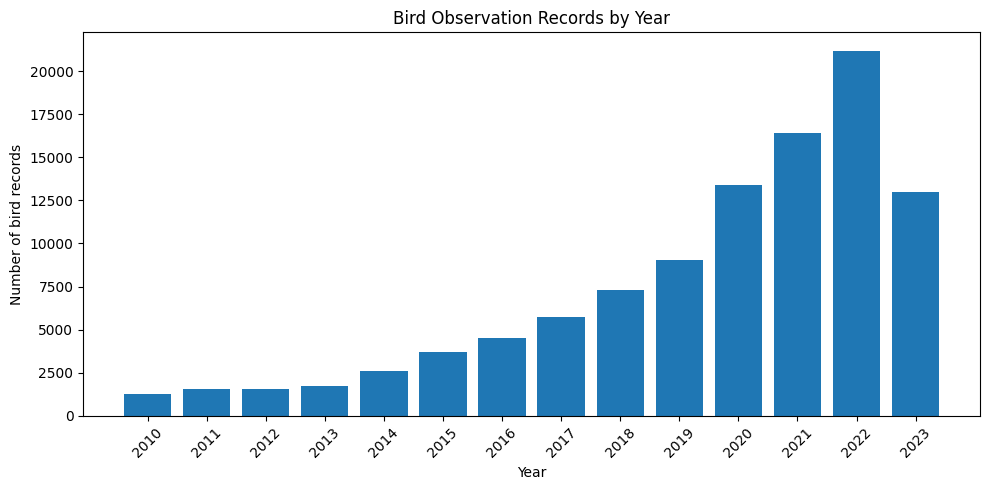

In [134]:
plt.figure(figsize=(10, 5))
plt.bar(
    records_by_year["year"].astype(str),
    records_by_year["records"]
)
plt.xlabel("Year")
plt.ylabel("Number of bird records")
plt.title("Bird Observation Records by Year")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "bird_records_by_year.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Cell 34 — Records by species

Summarise records by recorded species name. Species scope remains subject to the review decisions above.


In [135]:
records_by_species = (
    analysis_ready
    .groupby(
        ["common_name", "scientific_name"]
    )
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)
display(records_by_species)


,common_name,scientific_name,records
7,Red-backed Flameback,Dinopium psarodes,12958
4,Crimson-fronted Barbet,Psilopogon rubricapillus,11637
16,Sri Lanka Hanging-Parrot,Loriculus beryllinus,10339
17,Sri Lanka Junglefowl,Gallus lafayettii,8871
24,Yellow-fronted Barbet,Psilopogon flavifrons,7613
15,Sri Lanka Green-Pigeon,Treron pompadora,7434
14,Sri Lanka Gray Hornbill,Ocyceros gingalensis,5999
1,Black-capped Bulbul,Rubigula melanictera,4969
6,Layard's Parakeet,Psittacula calthrapae,4113
3,Crimson-backed Flameback,Chrysocolaptes stricklandi,3123


### Cell 35 — Plot records by species

Plot record frequency by species. This is an observation-coverage summary, not relative abundance.


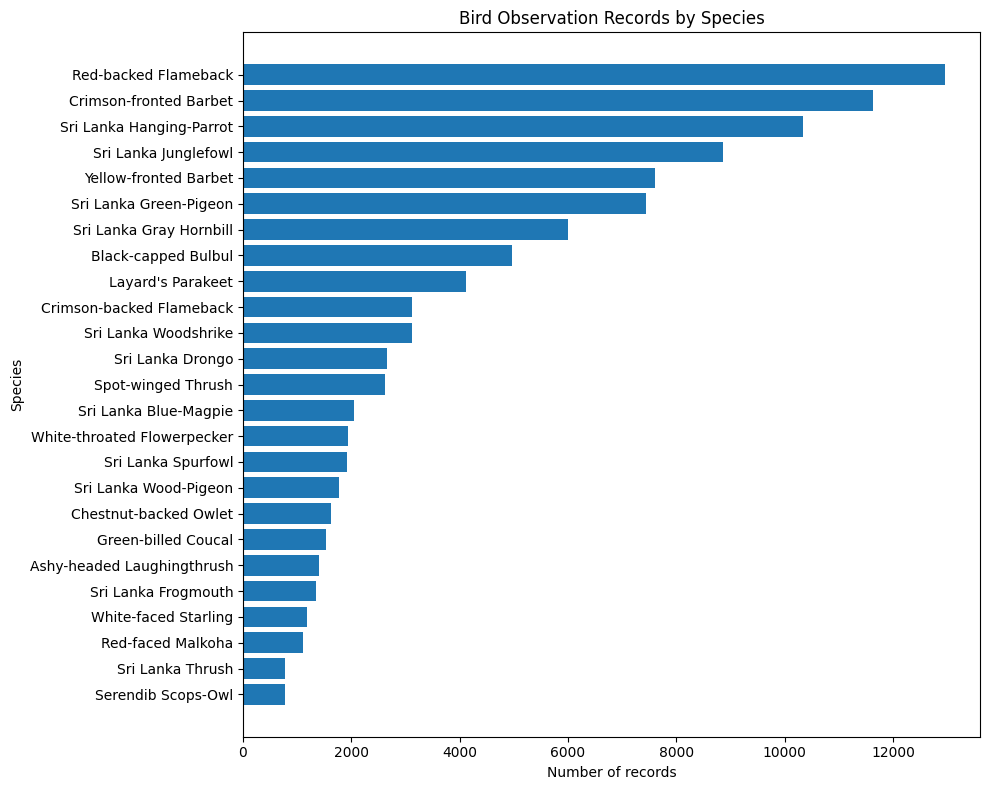

In [136]:
plt.figure(figsize=(10, 8))
plot_data = records_by_species.sort_values(
    "records",
    ascending=True
)
plt.barh(
    plot_data["common_name"],
    plot_data["records"]
)
plt.xlabel("Number of records")
plt.ylabel("Species")
plt.title("Bird Observation Records by Species")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "bird_records_by_species.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Cell 36 — Unique observation days

Count recorded dates. Unique dates are not independent checklists or survey events.


In [137]:
unique_days = (
    analysis_ready[
        "observation_date_parsed"
    ]
    .nunique()
)
print("Unique observation days:", unique_days)
daily_records = (
    analysis_ready
    .groupby("observation_date_parsed")
    .size()
    .reset_index(name="records")
)
display(daily_records.head())


Unique observation days: 3855


,observation_date_parsed,records
0,2010-01-01,26
1,2010-01-02,5
2,2010-01-03,21
3,2010-01-04,30
4,2010-01-05,41


### Cell 37 — Effort availability by year

Summarise effort availability by year. Supplied effort values can still fail validity checks.


In [138]:
effort_by_year = (
    analysis_ready
    .groupby("year")
    .agg(
        records=("source_row_id", "size"),
        duration_available_records=("duration_available", "sum"),
        distance_available_records=("distance_available", "sum"),
        effort_available_records=("effort_available", "sum"),
        complete_effort_records=("complete_effort_available", "sum")
    )
    .reset_index()
)
effort_by_year["duration_coverage_pct"] = (
    effort_by_year["duration_available_records"]
    / effort_by_year["records"]
    * 100
)
effort_by_year["distance_coverage_pct"] = (
    effort_by_year["distance_available_records"]
    / effort_by_year["records"]
    * 100
)
display(effort_by_year)


,year,records,duration_available_records,distance_available_records,effort_available_records,complete_effort_records,duration_coverage_pct,distance_coverage_pct
0,2010,1246,912,671,912,671,73.194222,53.852327
1,2011,1565,922,736,925,733,58.913738,47.028754
2,2012,1541,783,574,783,574,50.811162,37.248540
3,2013,1709,1125,1024,1125,1024,65.827970,59.918081
4,2014,2602,1472,1191,1581,1082,56.571868,45.772483
5,2015,3732,2275,1842,2282,1835,60.959271,49.356913
6,2016,4526,2946,2283,2953,2276,65.090588,50.441891
7,2017,5738,4690,3866,4706,3850,81.735796,67.375392
8,2018,7302,6575,5577,6577,5575,90.043824,76.376335
9,2019,9016,7874,6440,7885,6429,87.333629,71.428571


### Cell 38 — Check whether grid ID exists

Look for a cell-level identifier. Confirm its meaning before use: a grid-version identifier such as `lka_laea_5000m` is not a unique spatial cell.


In [139]:
possible_grid_columns = [
    "cell_id",
    "grid_id",
    "gridcell_id",
    "grid_cell_id"
]
GRID_COLUMN = None
for col in possible_grid_columns:
    if col in analysis_ready.columns:
        GRID_COLUMN = col
        break
print("Detected grid column:", GRID_COLUMN)


Detected grid column: None


### Cell 39 — Cell-year sampling bias table

Calculate cell-year sampling metrics when a valid cell identifier exists. An empty placeholder means the calculation is pending, not that sampling is zero.


In [140]:
if GRID_COLUMN is not None:
    sampling_bias_cell_year = (
        analysis_ready
        .groupby([GRID_COLUMN, "year"])
        .agg(
            records=("source_row_id", "size"),
            unique_observation_days=(
                "observation_date_parsed",
                "nunique"
            ),
            species_recorded=(
                "scientific_name",
                "nunique"
            ),
            duration_available_records=(
                "duration_available",
                "sum"
            ),
            distance_available_records=(
                "distance_available",
                "sum"
            ),
            effort_available_records=(
                "effort_available",
                "sum"
            ),
            complete_effort_available_records=(
                "complete_effort_available",
                "sum"
            )
        )
        .reset_index()
    )
    sampling_bias_cell_year[
        "effort_coverage_pct"
    ] = (
        sampling_bias_cell_year[
            "effort_available_records"
        ]
        / sampling_bias_cell_year["records"]
        * 100
    )
else:
    sampling_bias_cell_year = pd.DataFrame(
        columns=[
            "cell_id",
            "year",
            "records",
            "unique_observation_days",
            "species_recorded",
            "duration_available_records",
            "distance_available_records",
            "effort_available_records",
            "complete_effort_available_records",
            "effort_coverage_pct"
        ]
    )
    print(
        "Grid assignment is pending. "
        "Cell-year sampling metrics cannot yet be calculated."
    )
display(sampling_bias_cell_year.head())


Grid assignment is pending. Cell-year sampling metrics cannot yet be calculated.


,cell_id,year,records,unique_observation_days,species_recorded,duration_available_records,distance_available_records,effort_available_records,complete_effort_available_records,effort_coverage_pct


### Cell 40 — Identify highly sampled cells

Flag the upper tail of record counts using an exploratory 95th-percentile rule. This is a sampling-concentration flag, not a habitat-risk threshold.


In [141]:
HIGH_SAMPLING_THRESHOLD = None
if len(sampling_bias_cell_year) > 0:
    HIGH_SAMPLING_THRESHOLD = (
        sampling_bias_cell_year["records"]
        .quantile(0.95)
    )
    sampling_bias_cell_year[
        "highly_sampled"
    ] = (
        sampling_bias_cell_year["records"]
        >= HIGH_SAMPLING_THRESHOLD
    )
    print(
        "95th percentile threshold:",
        HIGH_SAMPLING_THRESHOLD
    )
    print(
        "Highly sampled cell-years:",
        sampling_bias_cell_year[
            "highly_sampled"
        ].sum()
    )
else:
    print(
        "High-sampling analysis pending grid assignment."
    )


High-sampling analysis pending grid assignment.


### Cell 41 — Spatial observation concentration using coordinates

Inspect repeated sampling at exact coordinate pairs using final coordinate fields. Rounded/shared coordinates may represent different observation events.


In [142]:
location_sampling = (
    analysis_ready
    .groupby(
        ["latitude_final", "longitude_final"]
    )
    .agg(
        records=("source_row_id", "size"),
        unique_days=("observation_date_parsed", "nunique"),
        species_recorded=("scientific_name", "nunique")
    )
    .reset_index()
)
display(
    location_sampling.sort_values(
        "records",
        ascending=False
    ).head(20)
)


,latitude_final,longitude_final,records,unique_days,species_recorded
1387,6.408960,80.445328,8087,588,25
1638,6.433354,80.418506,3866,245,25
1184,6.377266,80.136115,3286,434,15
2669,6.754182,80.934498,2800,467,12
4155,6.987599,80.422883,2077,241,25
4251,6.991838,80.405674,1842,180,23
1885,6.443461,80.417883,1762,188,25
1051,6.353175,81.472206,1597,547,15
1667,6.435952,80.419329,1455,125,25
5968,7.575104,80.628610,1403,134,12


### Cell 42 — Preliminary observation density map

Plot observation locations. Empty map regions mean no records in this input; they do not establish bird absence.


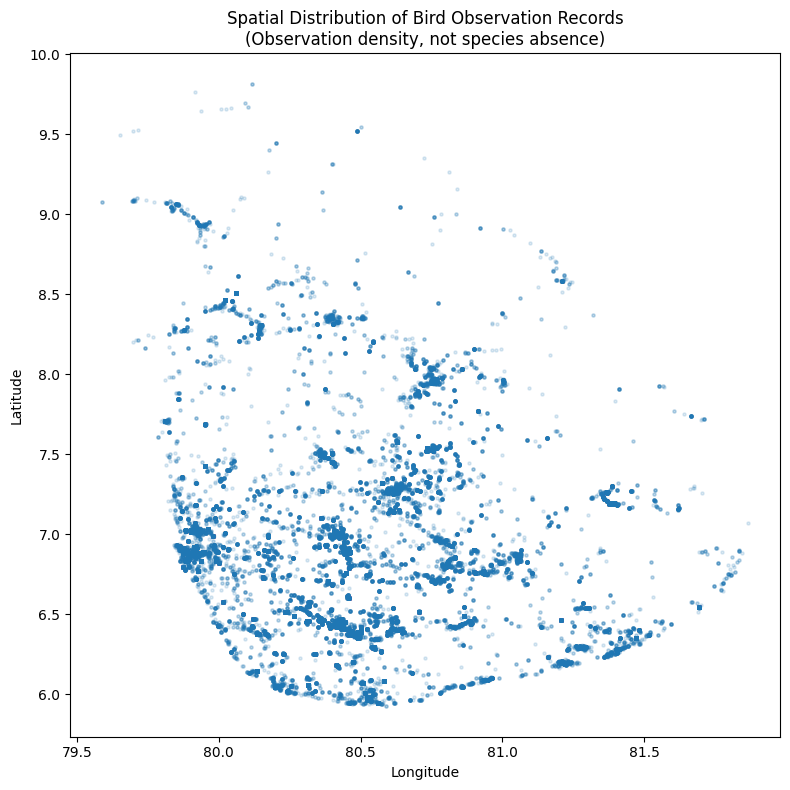

In [143]:
plt.figure(figsize=(8, 8))
plt.scatter(
    analysis_ready["longitude_final"],
    analysis_ready["latitude_final"],
    s=5,
    alpha=0.15
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    "Spatial Distribution of Bird Observation Records\n"
    "(Observation density, not species absence)"
)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "bird_observation_density_points.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Cell 43 — Spatial thinning sensitivity experiment

Use one retained row per species × cell × date as a sensitivity experiment only. Confirm grid identity and valid dates first; this is not a default deletion rule.


In [144]:
if GRID_COLUMN is not None:
    thinning_keys = [
        "scientific_name",
        GRID_COLUMN,
        "observation_date_parsed"
    ]
    thinned_data = (
        analysis_ready
        .sort_values("source_row_id")
        .drop_duplicates(
            subset=thinning_keys,
            keep="first"
        )
        .copy()
    )
    print(
        "Original analysis-ready records:",
        len(analysis_ready)
    )
    print(
        "After grid-day-species thinning:",
        len(thinned_data)
    )
    print(
        "Records removed:",
        len(analysis_ready) - len(thinned_data)
    )
else:
    thinned_data = pd.DataFrame()
    print(
        "Spatial thinning postponed because "
        "grid assignment is not yet available."
    )


Spatial thinning postponed because grid assignment is not yet available.


### Cell 44 — Presence combinations sensitivity

Compare unique cell-year-species presence combinations. Equal totals alone do not prove identical membership; compare the combinations themselves before claiming complete stability.


In [145]:
if GRID_COLUMN is not None:
    complete_presence = (
        analysis_ready[
            [GRID_COLUMN, "year", "scientific_name"]
        ]
        .drop_duplicates()
    )
    thinned_presence = (
        thinned_data[
            [GRID_COLUMN, "year", "scientific_name"]
        ]
        .drop_duplicates()
    )
    print(
        "Complete cell-year-species combinations:",
        len(complete_presence)
    )
    print(
        "Thinned cell-year-species combinations:",
        len(thinned_presence)
    )
else:
    print(
        "Presence-combination sensitivity pending grid assignment."
    )


Presence-combination sensitivity pending grid assignment.


## Save outputs and validate

### Cell 45 — Bird cleaning decisions

Save one row of cleaning decisions per source record for provenance. The table documents current decisions, including unresolved ones.


In [146]:
decision_columns = [
    "source_row_id",
    "common_name",
    "scientific_name",
    "possible_duplicate",
    "duplicate_decision",
    "effort_decision",
    "spatial_decision",
    "temporal_decision",
    "count_decision",
    "species_scope_status",
    "species_scope_pending",
    "analysis_status",
    "decision_reason"
]
bird_cleaning_decisions = df[
    decision_columns
].copy()
bird_cleaning_decisions.to_csv(
    PROCESSED_DIR
    / "bird_cleaning_decisions.csv",
    index=False
)
print(
    "Cleaning decisions:",
    len(bird_cleaning_decisions)
)


Cleaning decisions: 102929


### Cell 46 — Save analysis-ready dataset

Save the provisional eligible dataset under the requested filename. Release acceptance still requires completed boundary, taxonomy and other relevant reviews.


In [147]:
analysis_ready.to_csv(PROCESSED_DIR / "bird_observations_analysis_ready.csv", index=False)
print("Saved provisional analysis-ready dataset:", len(analysis_ready))


Saved provisional analysis-ready dataset: 102929


### Cell 47 — Save excluded/unresolved observations

Save excluded/unresolved rows separately for continued review and traceability.


In [148]:
excluded_or_unresolved.to_csv(PROCESSED_DIR / "bird_observations_excluded.csv", index=False)
print("Saved excluded/unresolved records:", len(excluded_or_unresolved))


Saved excluded/unresolved records: 0


### Cell 48 — Save sampling-bias outputs

Save sampling summaries and the cell-year result or pending placeholder. These outputs describe the provisional eligible view.


In [149]:
sampling_bias_cell_year.to_csv(PROCESSED_DIR / "sampling_bias_cell_year.csv", index=False)
records_by_year.to_csv(AUDIT_DIR / "bird_records_by_year.csv", index=False)
records_by_species.to_csv(AUDIT_DIR / "bird_records_by_species.csv", index=False)
effort_by_year.to_csv(AUDIT_DIR / "bird_effort_availability_by_year.csv", index=False)
location_sampling.to_csv(AUDIT_DIR / "bird_sampling_by_location.csv", index=False)
print("Sampling-bias outputs saved.")


Sampling-bias outputs saved.


### Cell 49 — Generate cleaning report automatically

Generate a report from the current notebook state. Review all completion claims; successful file creation does not complete evidence-dependent tasks.


In [150]:
species_unresolved = int(
    (species_scope["final_inclusion_status"] == "unresolved").sum()
)
species_included = int(
    (species_scope["final_inclusion_status"] == "include").sum()
)
species_excluded = int(
    (species_scope["final_inclusion_status"] == "exclude").sum()
)
report = f"""# Bird Observation Cleaning Report
## Work Package 2 — Complete Bird-Data Cleaning
### 1. Dataset
Input dataset:
`bird_observations_cleaning_draft.csv`
Total observations: **{len(df):,}**
Unique scientific names: **{df["scientific_name"].nunique()}**
Year range: **{df["year"].min()}–{df["year"].max()}**
---
## 2. Duplicate Review
Potential duplicate copies flagged: **{int(df["possible_duplicate"].sum()):,}**
Complete dataset size: **{len(df_complete):,}**
Deduplicated sensitivity dataset size: **{len(df_dedup):,}**
Potential duplicates were NOT automatically deleted from the primary
dataset because the supplied data do not contain a checklist/event
identifier that can establish whether identical rows represent repeated
ingestion or separate valid observations.
The complete dataset is therefore retained for the primary workflow,
while the deduplicated dataset is retained for sensitivity analysis.
---
## 3. Survey Effort Review
Missing duration records: **{int(df["duration_minutes"].isna().sum()):,}**
Missing distance records: **{int(df["effort_distance_km"].isna().sum()):,}**
Impossible effort records: **{int(df["impossible_effort"].sum()):,}**
Missing effort values were NOT replaced with zero.
Missing effort means that effort information is unavailable.
Occurrences with impossible effort values are retained as occurrence
evidence but should not contribute those invalid effort measurements to
effort-dependent analyses.
---
## 4. Spatial Review
Missing coordinate records: **{int(df["coordinate_missing"].sum()):,}**
Globally invalid coordinate records:
**{int(df["coordinate_out_of_global_range"].sum()):,}**
Broad Sri Lanka screening candidates:
**{int(df["outside_sri_lanka_screen"].sum()):,}**
The broad coordinate envelope was used only to identify records requiring
review. It is not treated as an official Sri Lanka national boundary.
Manual spatial decisions use four statuses:
- keep
- correct
- exclude
- unresolved
No coordinate correction is invented automatically.
---
## 5. Species Scope
Species included after verification: **{species_included}**
Species excluded: **{species_excluded}**
Species still unresolved: **{species_unresolved}**
Taxonomy and endemic status are not guessed automatically.
Unresolved species remain explicitly flagged until verified using an
authoritative source.
---
## 6. Final Observation Status
Analysis-ready records: **{len(analysis_ready):,}**
Excluded or unresolved records:
**{len(excluded_or_unresolved):,}**
Rows with unresolved species scope:
**{int(df["species_scope_pending"].sum()):,}**
If species verification is incomplete, the analysis-ready dataset should
be considered provisional until `final_species_scope.csv` is frozen.
---
## 7. Sampling Bias
Records were summarized by year, species, observation date and location.
Grid-cell/year sampling analysis is {"available" if GRID_COLUMN is not None else "pending because a grid-cell identifier has not yet been assigned"}.
Highly sampled cell-years are identified using the 95th percentile of
record counts when grid data are available.
Spatial thinning is used only as a sensitivity experiment and does not
create absence information.
---
## 8. Important Ecological Interpretation
A missing bird observation means:
**the species was not recorded in the available observation data.**
It must NOT automatically be interpreted as:
**the species was absent from that location.**
This distinction is important because citizen-science observation data
are affected by uneven sampling effort and observer accessibility.
---
## 9. Reproducibility
Every original observation has a `source_row_id`.
Duplicate, effort, spatial, temporal, count and species-scope decisions
are recorded explicitly.
The workflow preserves the original values while creating derived
analysis fields and documented decisions.
"""
REPORT_FILE = (
    REPORT_DIR
    / "bird_cleaning_report.md"
)
REPORT_FILE.write_text(
    report,
    encoding="utf-8"
)
print("Report saved:")
print(REPORT_FILE)


Report saved:
/Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/reports/hri/bird_cleaning_report.md


### Cell 50 — Final validation

Check expected files and row accounting. File existence is an output check, not scientific acceptance of the data.


In [151]:
required_outputs = [
    PROCESSED_DIR / "bird_observations_analysis_ready.csv",
    PROCESSED_DIR / "bird_observations_excluded.csv",
    PROCESSED_DIR / "bird_cleaning_decisions.csv",
    PROCESSED_DIR / "final_species_scope.csv",
    PROCESSED_DIR / "sampling_bias_cell_year.csv",
    REPORT_DIR / "bird_cleaning_report.md"
]
print("=" * 70)
print("FINAL OUTPUT VALIDATION")
print("=" * 70)
all_exist = True
for file in required_outputs:
    exists = file.exists()
    print(
        "✓" if exists else "✗",
        file.name
    )
    if not exists:
        all_exist = False
print("\nDataset checks")
print("-" * 70)
print(
    "Original records:",
    f"{len(df):,}"
)
print(
    "Analysis-ready:",
    f"{len(analysis_ready):,}"
)
print(
    "Excluded/unresolved:",
    f"{len(excluded_or_unresolved):,}"
)
print(
    "Possible duplicates retained:",
    f"{int(df['possible_duplicate'].sum()):,}"
)
print(
    "Unique species:",
    df["scientific_name"].nunique()
)
print(
    "Source IDs unique:",
    df["source_row_id"].is_unique
)
print(
    "Missing effort converted to zero:",
    False
)
print(
    "Species scope unresolved:",
    int(
        (
            species_scope["final_inclusion_status"]
            == "unresolved"
        ).sum()
    )
)
print(
    "Grid assigned:",
    GRID_COLUMN is not None
)
print("\n" + "=" * 70)
if all_exist:
    print("ALL REQUIRED OUTPUT FILES CREATED SUCCESSFULLY.")
else:
    print("WARNING: One or more required files are missing.")


FINAL OUTPUT VALIDATION
✓ bird_observations_analysis_ready.csv
✓ bird_observations_excluded.csv
✓ bird_cleaning_decisions.csv
✓ final_species_scope.csv
✓ sampling_bias_cell_year.csv
✓ bird_cleaning_report.md

Dataset checks
----------------------------------------------------------------------
Original records: 102,929
Analysis-ready: 102,929
Excluded/unresolved: 0
Possible duplicates retained: 18,411
Unique species: 25
Source IDs unique: True
Missing effort converted to zero: False
Species scope unresolved: 25
Grid assigned: False

ALL REQUIRED OUTPUT FILES CREATED SUCCESSFULLY.


### Cell 51 — Load existing draft and preserve provenance

WP2 versioned reconciliation. Uses existing evidence and writes to `data/processed/hri/wp2_v1/`. Earlier outputs remain historical; this release supersedes their eligibility labels.


In [152]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import geopandas as gpd

root = next(p for base in [Path.cwd(), *Path.cwd().parents]
            for p in [base, base / 'components/habitat_risk']
            if (p / 'configs/study.json').exists())
release = root / 'data/processed/hri/wp2_v1'
release.mkdir(parents=True, exist_ok=True)
draft = root / 'data/interim/hri/bird_observations_cleaning_draft.csv'
birds = pd.read_csv(draft, low_memory=False)
if 'source_row_id' not in birds:
    birds.insert(0, 'source_row_id', np.arange(1, len(birds) + 1))
assert birds.source_row_id.is_unique
for col in ['possible_duplicate', 'invalid_date', 'date_fields_disagree', 'count_needs_review']:
    values = birds[col].astype(str).str.strip().str.lower().map({'true': True, 'false': False})
    assert values.notna().all(), f'Invalid Boolean flag: {col}'
    birds[col] = values
birds['reference_year'] = pd.to_datetime(birds.observation_date, errors='coerce').dt.year
birds['observation_day'] = pd.to_datetime(birds.observation_date, errors='coerce').dt.normalize()



### Cell 52 — Freeze observation species scope independently from vulnerability traits

WP2 versioned reconciliation. Uses existing evidence and writes to `data/processed/hri/wp2_v1/`. Earlier outputs remain historical; this release supersedes their eligibility labels.


In [153]:
traits = pd.read_csv(root / 'data/metadata/species_traits.csv')
assert traits.scientific_name.is_unique
assert set(birds.scientific_name) <= set(traits.scientific_name)
scope = traits[['scientific_name', 'accepted_scientific_name', 'endemic_status',
                'taxonomy_standard', 'taxonomy_source', 'endemic_source',
                'taxonomy_match_status', 'notes']].copy()
assert scope.endemic_status.isin(['yes', 'no']).all()
scope['final_inclusion_status'] = np.where(scope.endemic_status.eq('yes'), 'include', 'exclude')
scope['decision_date'] = '2026-10-05'
scope['decision_basis'] = 'Frozen endemic-only design; Clements 2025 names; existing sourced trait register'
scope['trait_status'] = 'Not approved for vulnerability scoring'
scope.to_csv(release / 'final_species_scope.csv', index=False)
birds = birds.merge(scope[['scientific_name', 'accepted_scientific_name', 'final_inclusion_status']],
                    on='scientific_name', how='left', validate='many_to_one')



### Cell 53 — Recheck national boundary and reuse verified grid assignments

WP2 versioned reconciliation. Uses existing evidence and writes to `data/processed/hri/wp2_v1/`. Earlier outputs remain historical; this release supersedes their eligibility labels.


In [154]:
config = json.loads((root / 'configs/study.json').read_text())
boundary_path = root / config['boundary_file']
boundary = gpd.read_file(boundary_path).to_crs(4326)
polygon = boundary.geometry.union_all()
locations = birds[['latitude', 'longitude']].drop_duplicates().copy()
locations['inside_boundary_verified'] = [
    polygon.covers(point) for point in gpd.points_from_xy(locations.longitude, locations.latitude)
]
assignments = pd.read_csv(root / 'data/interim/spatial/lka_laea_5000m_location_assignments.csv')
assert not assignments.duplicated(['latitude', 'longitude']).any()
locations = locations.merge(assignments[['latitude', 'longitude', 'cell_id']],
                            on=['latitude', 'longitude'], how='left', validate='one_to_one')
grid = gpd.read_file(root / 'data/interim/spatial/lka_laea_5000m_grid.geojson').to_crs(4326)
assert grid.cell_id.is_unique
geometries = grid.set_index('cell_id').geometry
locations['grid_verified'] = [
    pd.notna(cid) and cid in geometries.index and geometries.loc[cid].covers(point)
    for cid, point in zip(locations.cell_id, gpd.points_from_xy(locations.longitude, locations.latitude))
]
locations.to_csv(release / 'location_verification.csv', index=False)
birds = birds.merge(locations, on=['latitude', 'longitude'], how='left', validate='many_to_one')
birds['spatial_decision'] = np.where(birds.inside_boundary_verified & birds.grid_verified,
                                     'keep', 'withhold_boundary_or_mapping')
# Outside polygon does not prove the coordinates are wrong; retain without invented corrections.



### Cell 54 — Apply effort and eligibility decisions while retaining every source row

WP2 versioned reconciliation. Uses existing evidence and writes to `data/processed/hri/wp2_v1/`. Earlier outputs remain historical; this release supersedes their eligibility labels.


In [155]:
duration = pd.to_numeric(birds.duration_minutes, errors='coerce')
distance = pd.to_numeric(birds.effort_distance_km, errors='coerce')
birds['duration_minutes_valid'] = duration.where(duration.between(0, 1440))
birds['effort_distance_km_valid'] = distance.where(distance.ge(0) & np.isfinite(distance))
birds['effort_invalid'] = ((duration.notna() & birds.duration_minutes_valid.isna()) |
                           (distance.notna() & birds.effort_distance_km_valid.isna()))
birds['duration_available'] = birds.duration_minutes_valid.notna()
birds['distance_available'] = birds.effort_distance_km_valid.notna()
birds['effort_available'] = birds.duration_available | birds.distance_available
birds['analysis_status'] = 'eligible_occurrence'
birds['decision_reason'] = 'Included endemic; valid date/count; verified boundary and grid'
bad = (birds.invalid_date | birds.date_fields_disagree | birds.count_needs_review |
       ~birds.reference_year.between(2010, 2023) | birds.spatial_decision.ne('keep'))
birds.loc[bad, 'analysis_status'] = 'withheld_review'
birds.loc[bad, 'decision_reason'] = 'Date/count/period or boundary/grid review required; see individual flags'
birds.loc[birds.final_inclusion_status.eq('exclude'), 'analysis_status'] = 'excluded_scope'
birds.loc[birds.final_inclusion_status.eq('exclude'), 'decision_reason'] = 'Non-endemic under frozen observation taxonomy'
eligible = birds.loc[birds.analysis_status.eq('eligible_occurrence')].copy()
other = birds.loc[birds.analysis_status.ne('eligible_occurrence')].copy()
assert len(eligible) + len(other) == len(birds)
assert eligible.cell_id.notna().all()
birds.to_csv(release / 'bird_cleaning_decisions.csv', index=False)
eligible.to_csv(release / 'bird_observations_analysis_ready.csv', index=False)
other.to_csv(release / 'bird_observations_excluded_or_withheld.csv', index=False)



### Cell 55 — Compare exact duplicates and grid-day-species thinning on identical eligibility rules

WP2 versioned reconciliation. Uses existing evidence and writes to `data/processed/hri/wp2_v1/`. Earlier outputs remain historical; this release supersedes their eligibility labels.


In [156]:
keys = ['cell_id', 'reference_year', 'accepted_scientific_name']
dedup = eligible.loc[~eligible.possible_duplicate].copy()
thinned = eligible.sort_values('source_row_id').drop_duplicates(
    ['cell_id', 'observation_day', 'accepted_scientific_name'])
def presence_set(data):
    return set(data[keys].itertuples(index=False, name=None))
primary_presence = presence_set(eligible)
results = []
for name, frame in [('complete', eligible), ('deduplicated', dedup), ('thinned', thinned)]:
    combos = presence_set(frame)
    results.append({'scenario': name, 'records': len(frame), 'presence_combinations': len(combos),
                    'lost_combinations': len(primary_presence - combos),
                    'added_combinations': len(combos - primary_presence)})
    assert combos == primary_presence, f'Unexpected presence changes: {name}'
sensitivity = pd.DataFrame(results)
sensitivity.to_csv(release / 'duplicate_thinning_sensitivity.csv', index=False)
evidence = eligible.groupby(keys).agg(
    observation_record_count=('source_row_id', 'size'),
    possible_duplicate_records=('possible_duplicate', 'sum'),
    unique_days=('observation_day', 'nunique')).reset_index()
assert not evidence.duplicated(keys).any()
evidence.to_csv(release / 'hri_cell_year_species_evidence.csv', index=False)
sample = eligible.groupby(['cell_id', 'reference_year']).agg(
    records=('source_row_id', 'size'), unique_observation_days=('observation_day', 'nunique'),
    species_recorded=('accepted_scientific_name', 'nunique'),
    valid_duration_records=('duration_available', 'sum'),
    valid_distance_records=('distance_available', 'sum'),
    valid_effort_records=('effort_available', 'sum')).reset_index()
sample['highly_sampled'] = sample.records.ge(sample.records.quantile(.95))
sample['effort_coverage_pct'] = sample.valid_effort_records / sample.records * 100
sample.to_csv(release / 'sampling_bias_cell_year.csv', index=False)
# This table covers observed cell-years; missing rows are unknown, never bird absence.



### Cell 56 — Save a reproducible release report and input checksums

WP2 versioned reconciliation. Uses existing evidence and writes to `data/processed/hri/wp2_v1/`. Earlier outputs remain historical; this release supersedes their eligibility labels.


In [157]:
inputs = [draft, boundary_path, root / 'configs/study.json',
          root / 'data/metadata/species_traits.csv',
          root / 'data/interim/spatial/lka_laea_5000m_location_assignments.csv',
          root / 'data/interim/spatial/lka_laea_5000m_grid.geojson']
manifest = {str(p.relative_to(root)): hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs}
(release / 'input_checksums.json').write_text(json.dumps(manifest, indent=2) + '\n')
report = f'''# WP2 versioned cleaning release

Date: 2026-10-05. Source: existing cleaning draft; source-row IDs are scoped to its recorded checksum.

- Source records: {len(birds):,}; eligible occurrences: {len(eligible):,}; excluded/withheld: {len(other):,}.
- Recorded species scope: {int(scope.final_inclusion_status.eq('include').sum())} included; {int(scope.final_inclusion_status.eq('exclude').sum())} excluded.
- Outside-boundary locations: {int((~locations.inside_boundary_verified).sum())}; records: {int((~birds.inside_boundary_verified).sum())}.
- Invalid effort records retained with invalid measurement fields masked: {int(birds.effort_invalid.sum())}.
- Observed cell-years: {len(sample):,}; cell-year-species combinations: {len(evidence):,}.

## Decisions

Retain exact duplicates in primary evidence because event identity is unavailable. Deduplicated and thinned scenarios preserve exactly the same cell-year-species membership (verified by set equality). Record totals differ; they are not independent survey counts or abundance. Priority sensitivity awaits a defined priority method.

Use Clements 2025 as documented in the existing source register and [Avibase checklist](https://avibase.bsc-eoc.org/checklist.jsp?lang=EN&region=LK), rechecked 2026-10-05. Include Zoothera imbricata for occurrence evidence; its BirdLife assessment mismatch remains unresolved for vulnerability. Exclude Batrachostomus moniliger under endemic-only scope. This freezes the recorded species list, not a claim of complete national species coverage.

Boundary covers includes polygon edges. Outside-boundary points are withheld without changing coordinates or claiming their true location. Original rows and values remain in the decision ledger. All accepted mappings are checked against grid geometry. No missing effort is converted to zero. Sampling metrics use valid effort fields and observed cell-years only.

## Status and limitations

Duplicate review and occurrence sensitivity, effort cleaning, boundary eligibility, recorded species scope and observed cell-year sampling summaries are completed for this release. Recovery of original event identifiers and correction of withheld locations require new source evidence. Trait verification, ecological validation, HRI/priority sensitivity and model training are not completed by WP2.

Use this versioned release instead of the older root-level processed files. Older interim species evidence and unresolved review templates are historical preparation artifacts and have not been silently overwritten.
'''
(release / 'README.md').write_text(report)
print(report)
print(sensitivity.to_string(index=False))


# WP2 versioned cleaning release

Date: 2026-10-05. Source: existing cleaning draft; source-row IDs are scoped to its recorded checksum.

- Source records: 102,929; eligible occurrences: 101,535; excluded/withheld: 1,394.
- Recorded species scope: 24 included; 1 excluded.
- Outside-boundary locations: 17; records: 47.
- Invalid effort records retained with invalid measurement fields masked: 20.
- Observed cell-years: 3,713; cell-year-species combinations: 16,151.

## Decisions

Retain exact duplicates in primary evidence because event identity is unavailable. Deduplicated and thinned scenarios preserve exactly the same cell-year-species membership (verified by set equality). Record totals differ; they are not independent survey counts or abundance. Priority sensitivity awaits a defined priority method.

Use Clements 2025 as documented in the existing source register and [Avibase checklist](https://avibase.bsc-eoc.org/checklist.jsp?lang=EN&region=LK), rechecked 2026-10-05. Include Zooth